# Exploratory Data Analysis 
## Looking at data intending to get labelled spiked data to train the model

Hitting the API into a csv (for ease of use)

In [1]:
import requests
import pandas as pd
import time

url = "https://sacaqm.web.cern.ch/dbread.php"

sensor_ids = [
    "80F3DA5493DC", "80F3DA54B464", "80F3DA551440", "80F3DA5580BC",
    "80F3DA54E9F8", "80F3DA5474CC", "351901936252711", "80F3DA550AFC",
    "80F3DA53CDFC", "80F3DA543464", "80F3DA50BD74", "80F3DA53A570",
    "80F3DA545DE0", "80F3DA50B704", "80F3DA546CB8", "80F3DA547384",
    "80F3DA50F2C0", "80F3DA542D5C", "80F3DA50DE3C", "351901936738230",
    "80F3DA50E388", "80F3DA50EEC8", "80F3DA550F78", "80F3DA547534",
    "80F3DA55B134", "80F3DA54C238", "80F3DA50F530", "80F3DA559B2C",
    "80F3DA53FFDC", "80F3DA53E828", "80F3DA539154", "80F3DA5595B8",
    "80F3DA53D9E8", "80F3DA558250", "80F3DA540038", "80F3DA543A10",
    "80F3DA544CC0", "80F3DA54AD58", "80F3DA558BC0", "80F3DA5573F8",
    "80F3DA50DE58", "80F3DA557E14", "80F3DA542CDC", "80F3DA53D73C",
    "80F3DA542A94", "350976655351689", "80F3DA558DF0", "80F3DA557C08",
    "351901936738875", "004B122FD0F8", "1C6920945B00", "80F3DA558028",
    "80F3DA5544D4", "80F3DA558251", "80F3DA549348", "80F3DA55B124",
    "351901936739550", "80F3DA549B40", "351901935957088", "350976650247924"]

all_data = []

for sensor_id in sensor_ids:
    params = {
        "cmd": "get_sen55",
        "sensor_id": sensor_id,
        "from": "2026-06-15T00:00:00Z",
        "to": "2026-06-21T23:59:59Z"
    }

    try:
        response = requests.get(url, params=params)
        response.raise_for_status()
        data = response.json()

        if data:
            all_data.extend(data)
            print(f"Data fetched for sensor {sensor_id}")
        else:
            print(f"No data found for sensor {sensor_id}")

    except requests.RequestException as e:
        print(f"Error fetching data for sensor {sensor_id}: {e}")

    time.sleep(1)  # Sleep for 1 second to avoid overwhelming the server

# Convert the list of dictionaries to a DataFrame
df = pd.DataFrame(all_data)

df.to_csv("sacaqm_80_sensors_raw.csv", index=False)

Data fetched for sensor 80F3DA5493DC
Data fetched for sensor 80F3DA54B464
Data fetched for sensor 80F3DA551440
Data fetched for sensor 80F3DA5580BC
Data fetched for sensor 80F3DA54E9F8
Data fetched for sensor 80F3DA5474CC
Data fetched for sensor 351901936252711
Data fetched for sensor 80F3DA550AFC
Data fetched for sensor 80F3DA53CDFC
Data fetched for sensor 80F3DA543464
Data fetched for sensor 80F3DA50BD74
Data fetched for sensor 80F3DA53A570
Data fetched for sensor 80F3DA545DE0
Data fetched for sensor 80F3DA50B704
Data fetched for sensor 80F3DA546CB8
Data fetched for sensor 80F3DA547384
Data fetched for sensor 80F3DA50F2C0
Data fetched for sensor 80F3DA542D5C
Data fetched for sensor 80F3DA50DE3C
Data fetched for sensor 351901936738230
Data fetched for sensor 80F3DA50E388
Data fetched for sensor 80F3DA50EEC8
Data fetched for sensor 80F3DA550F78
Data fetched for sensor 80F3DA547534
Data fetched for sensor 80F3DA55B134
Data fetched for sensor 80F3DA54C238
Data fetched for sensor 80F3DA50

In [7]:
import requests
import pandas as pd
import time

df = pd.read_csv("sacaqm_80_sensors_raw.csv")
# get all data types in the DataFrame
print(df.dtypes)

id               int64
sensor_id       object
timestamp       object
temperature    float64
humidity       float64
pm1p0          float64
pm2p5          float64
pm4p0          float64
pm10p0         float64
voc            float64
nox            float64
co2            float64
latitude       float64
longitude      float64
altitude       float64
area            object
operator        object
cellid          object
dba            float64
dtype: object


In [8]:
# convert object columns to proper data types
df['id'] = pd.to_numeric(df['id'], errors='coerce')
df['sensor_id'] = df['sensor_id'].astype(str)
df['timestamp'] = pd.to_datetime(df['timestamp'])
df['temperature'] = pd.to_numeric(df['temperature'], errors='coerce')
df['humidity'] = pd.to_numeric(df['humidity'], errors='coerce')
df['pm2p5'] = pd.to_numeric(df['pm2p5'], errors='coerce')
df['pm1p0'] = pd.to_numeric(df['pm1p0'], errors='coerce')
df['pm10p0'] = pd.to_numeric(df['pm10p0'], errors='coerce')
df['pm4p0'] = pd.to_numeric(df['pm4p0'], errors='coerce')
df['voc'] = pd.to_numeric(df['voc'], errors='coerce')
df['nox'] = pd.to_numeric(df['nox'], errors='coerce')
df['co2'] = pd.to_numeric(df['co2'], errors='coerce')
df['latitude'] = pd.to_numeric(df['latitude'], errors='coerce')
df['longitude'] = pd.to_numeric(df['longitude'], errors='coerce')
df['altitude'] = pd.to_numeric(df['altitude'], errors='coerce')
df['area'] = df['area'].astype(str)
df['operator'] = df['operator'].astype(str)
df['cellid'] = df['cellid'].astype(str)
df['dba'] = pd.to_numeric(df['dba'], errors='coerce')

In [9]:
# Number of unique station IDs
print(df['sensor_id'].nunique())

# print the unique station IDs
print(df['sensor_id'].unique())

60
['80F3DA5493DC' '80F3DA54B464' '80F3DA551440' '80F3DA5580BC'
 '80F3DA54E9F8' '80F3DA5474CC' '351901936252711' '80F3DA550AFC'
 '80F3DA53CDFC' '80F3DA543464' '80F3DA50BD74' '80F3DA53A570'
 '80F3DA545DE0' '80F3DA50B704' '80F3DA546CB8' '80F3DA547384'
 '80F3DA50F2C0' '80F3DA542D5C' '80F3DA50DE3C' '351901936738230'
 '80F3DA50E388' '80F3DA50EEC8' '80F3DA550F78' '80F3DA547534'
 '80F3DA55B134' '80F3DA54C238' '80F3DA50F530' '80F3DA559B2C'
 '80F3DA53FFDC' '80F3DA53E828' '80F3DA539154' '80F3DA5595B8'
 '80F3DA53D9E8' '80F3DA558250' '80F3DA540038' '80F3DA543A10'
 '80F3DA544CC0' '80F3DA54AD58' '80F3DA558BC0' '80F3DA5573F8'
 '80F3DA50DE58' '80F3DA557E14' '80F3DA542CDC' '80F3DA53D73C'
 '80F3DA542A94' '350976655351689' '80F3DA558DF0' '80F3DA557C08'
 '351901936738875' '004B122FD0F8' '1C6920945B00' '80F3DA558028'
 '80F3DA5544D4' '80F3DA558251' '80F3DA549348' '80F3DA55B124'
 '351901936739550' '80F3DA549B40' '351901935957088' '350976650247924']


In [10]:
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.sort_values(['sensor_id', 'timestamp']) # Sort the DataFrame by sensor_id and timestamp

sensor_summary = df.groupby('sensor_id').agg(
    readings=("pm2p5", "count"),
    start_time=('timestamp', 'min'),
    end_time=('timestamp', 'max'),
    mean_pm2p5=('pm2p5', 'mean'),
    median_pm2p5=('pm2p5', 'median'),
    max_pm2p5=('pm2p5', 'max'),
    missing_readings=("pm2p5", lambda x: x.isna().sum())
).reset_index()

sensor_summary.sort_values(by='readings', ascending=False, inplace=True)
sensor_summary.head(20)

,sensor_id,readings,start_time,end_time,mean_pm2p5,median_pm2p5,max_pm2p5,missing_readings
39,80F3DA54AD58,2001,2026-06-15 00:03:02,2026-06-21 23:56:19,2.057721,1.5,8.1,0
43,80F3DA550AFC,2000,2026-06-15 00:01:23,2026-06-21 23:58:22,1.850150,1.2,7.9,0
51,80F3DA5580BC,2000,2026-06-15 00:01:52,2026-06-21 23:59:55,1.754650,1.1,10.6,0
45,80F3DA551440,1994,2026-06-15 00:03:48,2026-06-21 23:55:56,3.860231,0.9,2060.6,0
22,80F3DA53E828,1993,2026-06-15 00:02:29,2026-06-21 23:59:48,0.929353,0.7,4.3,0
28,80F3DA543464,1993,2026-06-15 00:04:55,2026-06-21 23:58:24,2.134722,1.0,36.9,0
56,80F3DA5595B8,1991,2026-06-15 00:00:35,2026-06-21 23:59:51,1.066499,0.8,5.9,0
25,80F3DA542A94,1991,2026-06-15 00:02:35,2026-06-21 23:55:25,1.736715,0.9,10.5,0
13,80F3DA50E388,1988,2026-06-15 00:00:03,2026-06-21 23:55:38,14.574195,10.1,196.5,0
12,80F3DA50DE58,1988,2026-06-15 00:03:38,2026-06-21 23:55:33,10.780936,7.9,107.1,0


## If we retrive all the data from our API, the actual time period of all our data runs through is: 2026-03-04 08:13:38 to 2026-06-22 12:47:41

In [11]:
missing_summary = df.groupby("sensor_id")["pm2p5"].apply(
    lambda x: x.isna().mean() * 100
).sort_values(ascending=False)

missing_summary.head(20)

sensor_id
004B122FD0F8       0.0
1C6920945B00       0.0
350976650247924    0.0
350976655351689    0.0
351901935957088    0.0
351901936252711    0.0
351901936738230    0.0
351901936738875    0.0
351901936739550    0.0
80F3DA50B704       0.0
80F3DA50BD74       0.0
80F3DA50DE3C       0.0
80F3DA50DE58       0.0
80F3DA50E388       0.0
80F3DA50EEC8       0.0
80F3DA50F2C0       0.0
80F3DA50F530       0.0
80F3DA539154       0.0
80F3DA53A570       0.0
80F3DA53CDFC       0.0
Name: pm2p5, dtype: float64

No data is missing from our set

In [12]:
pm25_stats = df.groupby("sensor_id")["pm2p5"].describe()
pm25_stats.sort_values("max", ascending=False).head(20)

,count,mean,std,min,25%,50%,75%,max
sensor_id,,,,,,,,
80F3DA557C08,1985.0,42.168514,279.291338,0.00,0.00,0.00,0.000,6016.00
350976650247924,1.0,5758.000000,NaN,5758.00,5758.00,5758.00,5758.000,5758.00
351901935957088,1.0,5758.000000,NaN,5758.00,5758.00,5758.00,5758.000,5758.00
80F3DA551440,1994.0,3.860231,49.282678,0.00,0.40,0.90,1.700,2060.60
80F3DA546CB8,1942.0,11.347219,55.773510,0.40,2.60,4.70,10.400,1716.80
80F3DA55B134,1979.0,12.780293,28.395106,0.30,3.10,8.10,14.700,989.60
80F3DA53CDFC,1962.0,17.654179,34.012375,1.50,6.00,8.90,17.875,537.80
80F3DA542CDC,1958.0,5.290603,12.721243,0.20,1.50,2.40,5.100,387.90
80F3DA54B464,1982.0,11.239758,22.558639,0.70,4.30,6.90,10.900,302.40


In [13]:
#dropping columns from the DataFrame because they are empty
df.drop(columns=["longitude", "latitude", "altitude", "dba"], inplace=True)

# making dataframe
dashboard_df = pd.read_csv("sacaqm_dashboard_sensor_metadata.csv")
dashboard_df["sensor_id"] = dashboard_df["sensor_id"].astype(str)
dashboard_df["station"] = dashboard_df["station"].astype(str)

print(dashboard_df.dtypes)

sensor_id       object
station         object
province        object
city            object
description     object
longitude      float64
latitude       float64
last_seen       object
dtype: object


In [14]:
small_df = dashboard_df[["sensor_id", "station", "longitude", "latitude"]].copy()

df_full = pd.merge(df, small_df, on="sensor_id", how="left")

df_full.head()

,id,sensor_id,timestamp,temperature,humidity,pm1p0,pm2p5,pm4p0,pm10p0,voc,nox,co2,area,operator,cellid,station,longitude,latitude
0,5185526,004B122FD0F8,2026-06-15 01:19:56,16.81,59.03,6.13,7.46,8.66,8.56,2.32,0.94,413.0,office,wifi,wifi,Midvaal Sicelo Library,27.986431,-26.553092
1,5187401,004B122FD0F8,2026-06-15 03:43:24,18.25,58.51,6.57,7.09,8.01,10.44,2.02,1.07,422.0,office,wifi,wifi,Midvaal Sicelo Library,27.986431,-26.553092
2,5191572,004B122FD0F8,2026-06-15 09:02:08,20.12,49.03,6.11,6.63,8.90,10.87,2.36,1.02,403.0,office,wifi,wifi,Midvaal Sicelo Library,27.986431,-26.553092
3,5196680,004B122FD0F8,2026-06-15 15:24:11,22.34,40.71,5.88,6.45,7.23,8.56,6.03,3.11,625.0,office,wifi,wifi,Midvaal Sicelo Library,27.986431,-26.553092
4,5200504,004B122FD0F8,2026-06-15 20:08:14,19.18,49.18,5.56,6.78,7.98,8.72,6.06,3.24,498.0,office,wifi,wifi,Midvaal Sicelo Library,27.986431,-26.553092


In [15]:
df_full.sort_values("pm2p5", ascending=False)[
    ["timestamp", "sensor_id", "pm2p5"]
].head(30)

,timestamp,sensor_id,pm2p5
77505,2026-06-20 01:03:05,80F3DA557C08,6016.0
1767,2026-06-21 22:46:22,351901935957088,5758.0
118,2026-06-21 23:04:32,350976650247924,5758.0
76478,2026-06-16 10:19:10,80F3DA557C08,5332.8
77293,2026-06-19 07:08:25,80F3DA557C08,4344.7
77389,2026-06-19 15:15:04,80F3DA557C08,3684.6
77172,2026-06-18 20:56:33,80F3DA557C08,2995.0
76306,2026-06-15 19:26:05,80F3DA557C08,2761.6
76549,2026-06-16 16:19:05,80F3DA557C08,2431.4
77355,2026-06-19 12:22:07,80F3DA557C08,2082.0


1. Resample the data to hourly frequency
2. Sort each sensor’s readings in time order
3. Calculate a rolling average for each sensor
4. Calculate a rolling standard deviation for each sensor
5. Convert the current PM2.5 value into a z-score
6. Flag rows where the z-score is high and PM2.5 increased

In [16]:
# Resample the data to hourly frequency so that we can calculate rolling statistics and z-scores for spike detection 
hourly = (
    df_full
    .set_index("timestamp")
    .groupby(["sensor_id", "station"])["pm2p5"]
    .resample("1H")
    .mean()
    .reset_index()
)

hourly = hourly.sort_values(["sensor_id", "timestamp"])

hourly["rolling_mean"] = hourly.groupby("sensor_id")["pm2p5"].transform(
    lambda x: x.rolling(window=24, min_periods=6).mean()
)

hourly["rolling_std"] = hourly.groupby("sensor_id")["pm2p5"].transform(
    lambda x: x.rolling(window=24, min_periods=6).std()
)

hourly["z_score"] = (
    hourly["pm2p5"] - hourly["rolling_mean"]
) / hourly["rolling_std"]

hourly["pm2p5_diff"] = hourly.groupby("sensor_id")["pm2p5"].diff() # 

spike_candidates = hourly[
    (hourly["z_score"] > 3) &
    (hourly["pm2p5_diff"] > 0)
].copy()

spike_candidates.sort_values("z_score", ascending=False).head(30)

# print(f"Total number of spike candidates detected: {len(spike_candidates)}")

C:\Users\okwuk\AppData\Local\Temp\ipykernel_23180\4131860224.py:6: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  .resample("1H")


,sensor_id,station,timestamp,pm2p5,rolling_mean,rolling_std,z_score,pm2p5_diff
4428,80F3DA546CB8,Gstad West,2026-06-17 22:00:00,492.041667,30.743971,98.584335,4.679219,481.925000
2245,80F3DA53CDFC,Wrdm Hectorton,2026-06-17 17:00:00,163.083333,15.512144,31.561774,4.675630,152.283333
5092,80F3DA549348,Lavin,2026-06-17 14:00:00,34.590000,4.770086,6.390412,4.666352,30.462727
5743,80F3DA54B464,Boksburg 1,2026-06-16 17:00:00,234.508333,18.713138,46.431426,4.647611,197.644697
8034,80F3DA558BC0,Kyalami 1,2026-06-21 12:00:00,30.350000,3.734943,5.729063,4.645622,27.395455
6580,80F3DA551440,SYNERGIA Leeds 4,2026-06-16 20:00:00,208.141667,12.188937,42.220208,4.641207,206.641667
2330,80F3DA53CDFC,Wrdm Hectorton,2026-06-21 06:00:00,108.733333,10.962879,21.119818,4.629323,106.216667
2073,80F3DA53A570,Vlakfontein 599,2026-06-17 12:00:00,56.041667,8.031313,10.557798,4.547383,46.205303
3410,80F3DA542CDC,Rusfontein 1,2026-06-17 12:00:00,55.890000,5.862001,11.045663,4.529198,39.390000
6673,80F3DA551440,SYNERGIA Leeds 4,2026-06-20 17:00:00,8.200000,0.886490,1.644500,4.447254,7.766667


In [17]:
# Summary of detected spike candidates per sensor
sensor_spike_summary = (
    hourly.groupby("sensor_id")
    .agg(
        readings=("pm2p5", "count"),
        spike_candidates=("z_score", lambda x: ((x > 3)).sum()),
        mean_pm25=("pm2p5", "mean"),
        max_pm25=("pm2p5", "max"),
        max_z_score=("z_score", "max")
    )
    .sort_values("spike_candidates", ascending=False)
)

sensor_spike_summary.head(20)

,readings,spike_candidates,mean_pm25,max_pm25,max_z_score
sensor_id,,,,,
80F3DA542CDC,168,8,5.359535,67.458333,4.529198
80F3DA557C08,168,8,42.170031,501.858333,4.180617
80F3DA50F530,168,7,17.572446,90.558333,4.031067
80F3DA545DE0,168,6,6.914928,37.458333,4.306967
80F3DA551440,168,6,3.830910,208.141667,4.641207
80F3DA558250,164,6,14.292684,76.316667,3.879275
80F3DA54B464,168,5,11.236680,234.508333,4.647611
80F3DA543464,168,5,2.149241,24.958333,4.378903
80F3DA5580BC,168,5,1.758590,8.625000,3.573467


## Showing example graph for time series data of sensors that have spike candidates

In [18]:
selected_sensors = sensor_spike_summary.head(8).index.tolist()
selected_sensors

['80F3DA542CDC',
 '80F3DA557C08',
 '80F3DA50F530',
 '80F3DA545DE0',
 '80F3DA551440',
 '80F3DA558250',
 '80F3DA54B464',
 '80F3DA543464']

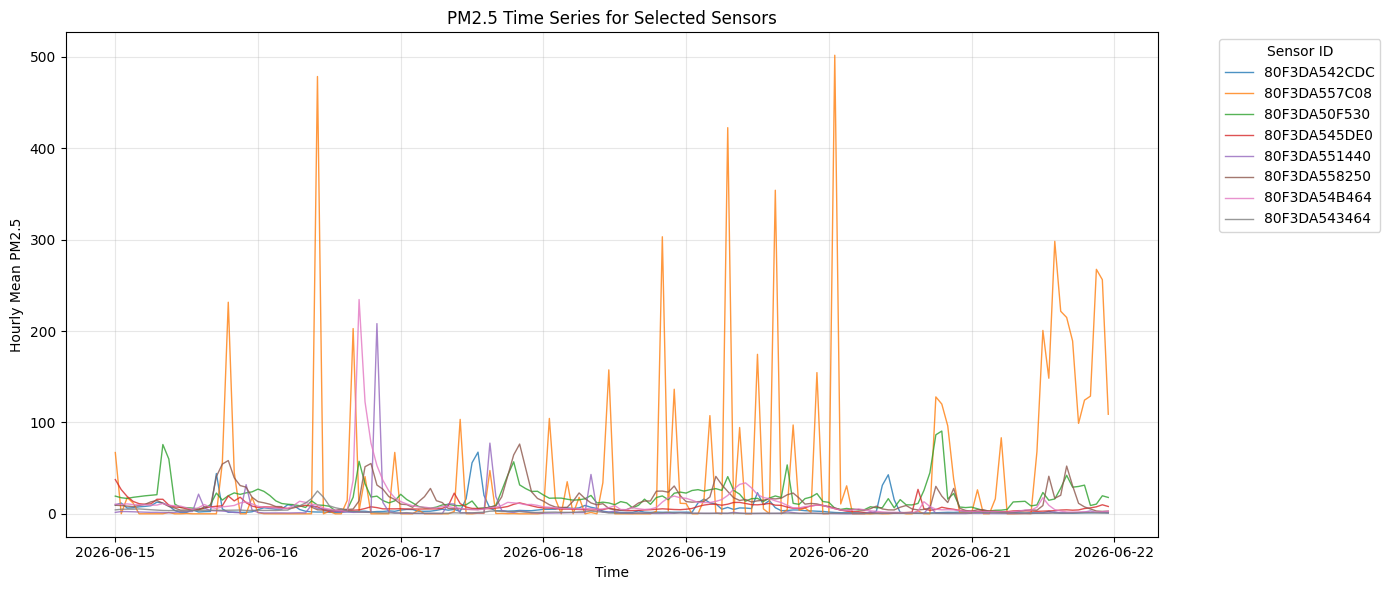

In [19]:
# Visualize the PM2.5 time series for the selected sensors
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

for sensor_id in selected_sensors:
    temp = hourly[hourly["sensor_id"] == sensor_id]

    plt.plot(
        temp["timestamp"],
        temp["pm2p5"],
        linewidth=1,
        alpha=0.8,
        label=str(sensor_id)
    )

plt.title("PM2.5 Time Series for Selected Sensors")
plt.xlabel("Time")
plt.ylabel("Hourly Mean PM2.5")
plt.legend(title="Sensor ID", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Example sensors time series graph with labels at the specific time there is a suspected spike based on the z_score constraint

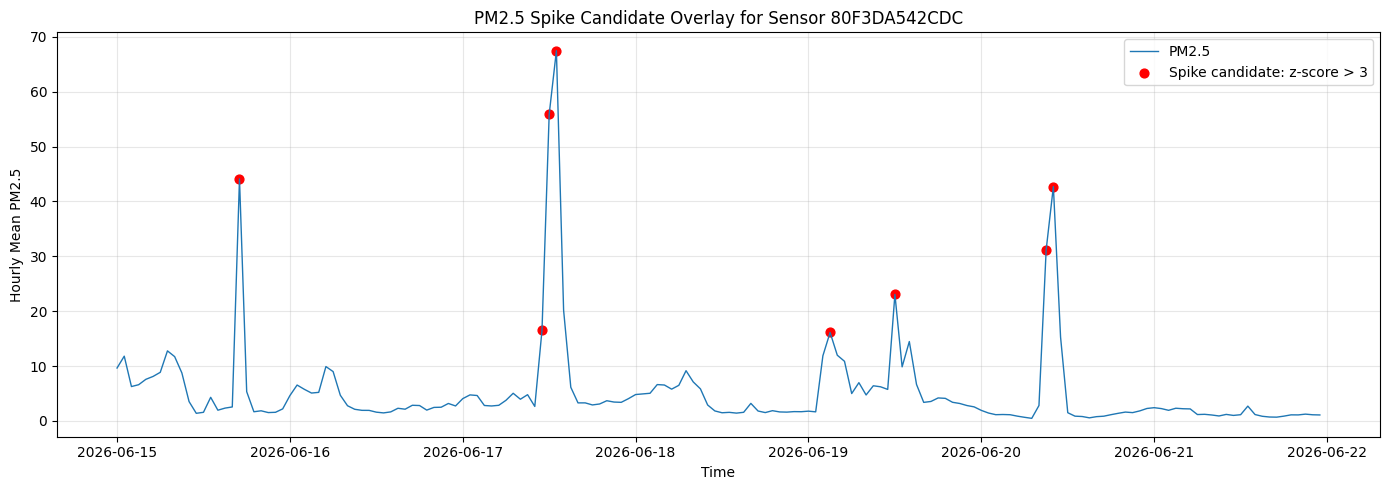

In [20]:
# spike candidate overlay
sensor_to_plot = selected_sensors[0]

temp = hourly[hourly["sensor_id"] == sensor_to_plot]
spikes = temp[
    (temp["z_score"] > 3) &
    (temp["pm2p5_diff"] > 0)
]

plt.figure(figsize=(14, 5))

plt.plot(
    temp["timestamp"],
    temp["pm2p5"],
    linewidth=1,
    label="PM2.5"
)

plt.scatter(
    spikes["timestamp"],
    spikes["pm2p5"],
    color="red",
    s=40,
    label="Spike candidate: z-score > 3"
)

plt.title(f"PM2.5 Spike Candidate Overlay for Sensor {sensor_to_plot}")
plt.xlabel("Time")
plt.ylabel("Hourly Mean PM2.5")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [21]:
# writing df_full to a CSV file
df_full.to_csv("sacaqm_80_sensors_full.csv", index=False)

In [22]:
# Check rows where both longitude and latitude are missing
df_null_coords = df_full[
    df_full["longitude"].isnull() & df_full["latitude"].isnull()
]

print(f"Number of rows with null coordinates: {len(df_null_coords)}")

# Show unique sensor IDs with missing coordinates
missing_sensors = (
    df_null_coords[["sensor_id", "longitude", "latitude"]]
    .drop_duplicates()
)

print(f"Number of unique sensors with null coordinates: {missing_sensors['sensor_id'].nunique()}")
print(missing_sensors)

Number of rows with null coordinates: 3628
Number of unique sensors with null coordinates: 7
             sensor_id  longitude  latitude
118    350976650247924        NaN       NaN
119    350976655351689        NaN       NaN
1767   351901935957088        NaN       NaN
1768   351901936252711        NaN       NaN
3723   351901936738875        NaN       NaN
4319   351901936739550        NaN       NaN
80045     80F3DA558028        NaN       NaN


In [23]:
# drop these sensors from the df_full DataFrame
sensors_to_drop = missing_sensors["sensor_id"].tolist()
df_full = df_full.drop(df_full[df_full["sensor_id"].isin(sensors_to_drop)].index)

I dropped these because they don't have a station or a longitude and latitude value

## Grouping neighbourhood stations based on the distances between them. Boolean neighbourhood matrix shows which stations meet the "less than 5km" criteria. 'neighbours_within_5km' matrix allows us to see which sensors are neighbours.

In [24]:
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import haversine_distances

# One row per sensor
station_coords = (
    df_full[["sensor_id", "station", "latitude", "longitude"]]
    .dropna(subset=["latitude", "longitude"])
    .drop_duplicates(subset=["sensor_id"]) # duplicate sensor_id rows due to time series data
    .reset_index(drop=True)
)

# Convert coordinates to radians
coords_rad = np.radians(
    station_coords[["latitude", "longitude"]].astype(float).values
)

# Distance matrix in km
dist_matrix = haversine_distances(coords_rad) * 6371

# Neighbour threshold
threshold_km = 5

# Boolean neighbour matrix
neighbour_matrix = dist_matrix < threshold_km
np.fill_diagonal(neighbour_matrix, False)

print(neighbour_matrix.shape)

(53, 53)


In [25]:
neighbour_df = pd.DataFrame(
    neighbour_matrix,
    index=station_coords["sensor_id"],
    columns=station_coords["sensor_id"]
)

neighbour_df.head()

sensor_id,004B122FD0F8,1C6920945B00,351901936738230,80F3DA50B704,80F3DA50BD74,80F3DA50DE3C,80F3DA50DE58,80F3DA50E388,80F3DA50EEC8,80F3DA50F2C0,...,80F3DA557E14,80F3DA5580BC,80F3DA558250,80F3DA558251,80F3DA558BC0,80F3DA558DF0,80F3DA5595B8,80F3DA559B2C,80F3DA55B124,80F3DA55B134
sensor_id,,,,,,,,,,,,,,,,,,,,,
004B122FD0F8,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1C6920945B00,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
351901936738230,False,False,False,False,False,False,True,False,False,False,...,True,False,False,True,False,False,False,False,False,False
80F3DA50B704,False,False,False,False,False,False,True,False,False,False,...,True,False,False,False,False,False,False,False,False,False
80F3DA50BD74,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [26]:
neighbour_rows = []

for i, sensor_id in enumerate(station_coords["sensor_id"]):
    neighbour_indices = np.where(neighbour_matrix[i])[0]

    for j in neighbour_indices:
        neighbour_rows.append({
            "sensor_id": sensor_id,
            "station": station_coords.loc[i, "station"],
            "neighbour_sensor_id": station_coords.loc[j, "sensor_id"],
            "neighbour_station": station_coords.loc[j, "station"],
            "distance_km": dist_matrix[i, j]
        })

neighbours_within_5km = pd.DataFrame(neighbour_rows)

neighbours_within_5km.head(20)

,sensor_id,station,neighbour_sensor_id,neighbour_station,distance_km
0,351901936738230,Origin Centre (db),80F3DA50DE58,Northwold Drive,3.882644
1,351901936738230,Origin Centre (db),80F3DA5493DC,11 Alexander Ferrierasdorp,1.765730
2,351901936738230,Origin Centre (db),80F3DA557E14,Westdene 2,4.415646
3,351901936738230,Origin Centre (db),80F3DA558251,Node at Majestic Towers,1.867351
4,80F3DA50B704,Montgomery Park Node 1,80F3DA50DE58,Northwold Drive,4.383942
5,80F3DA50B704,Montgomery Park Node 1,80F3DA53D73C,Parkhurst 1,3.495640
6,80F3DA50B704,Montgomery Park Node 1,80F3DA53FFDC,Parkhurst 2,3.950889
7,80F3DA50B704,Montgomery Park Node 1,80F3DA540038,Victory Park 1,3.927428
8,80F3DA50B704,Montgomery Park Node 1,80F3DA547384,NorthCliff,4.580760
9,80F3DA50B704,Montgomery Park Node 1,80F3DA557E14,Westdene 2,2.622553


In [27]:
neighbour_counts = (
    neighbours_within_5km
    .groupby(["sensor_id", "station"])
    .size()
    .reset_index(name="num_neighbours_within_5km")
    .sort_values("num_neighbours_within_5km", ascending=False)
)

neighbour_counts.head(20)

,sensor_id,station,num_neighbours_within_5km
1,80F3DA50B704,Montgomery Park Node 1,6
4,80F3DA50DE58,Northwold Drive,6
13,80F3DA53FFDC,Parkhurst 2,5
10,80F3DA53D73C,Parkhurst 1,5
14,80F3DA540038,Victory Park 1,5
5,80F3DA50E388,Blairgowrie,4
0,351901936738230,Origin Centre (db),4
3,80F3DA50DE3C,Benmore Gardens,3
19,80F3DA547384,NorthCliff,3
31,80F3DA557E14,Westdene 2,3


## Plotting a graph showing neighbours specifically in the Gauteng region, just as an observation.

In [28]:
# Rough Gauteng bounding box
gauteng_mask = (
    (station_coords["longitude"] >= 27.0) &
    (station_coords["longitude"] <= 29.5) &
    (station_coords["latitude"] >= -27.0) &
    (station_coords["latitude"] <= -25.0)
)

gauteng_coords = station_coords[gauteng_mask].reset_index(drop=True)

print("Number of Gauteng-area sensors:", len(gauteng_coords))

Number of Gauteng-area sensors: 43


In [29]:
# Compute distance matrix and neighbour matrix for Gauteng sensors
from sklearn.metrics.pairwise import haversine_distances

coords_rad_gauteng = np.radians(
    gauteng_coords[["latitude", "longitude"]].astype(float).values
)

dist_matrix_gauteng = haversine_distances(coords_rad_gauteng) * 6371

threshold_km = 5
neighbour_matrix_gauteng = dist_matrix_gauteng < threshold_km
np.fill_diagonal(neighbour_matrix_gauteng, False)

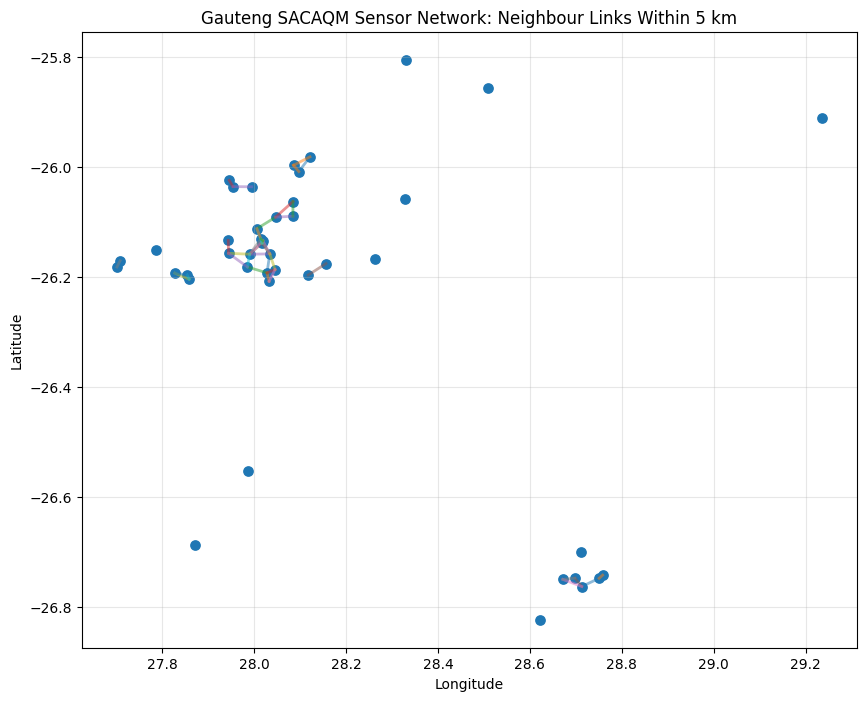

In [30]:
plt.figure(figsize=(10, 8))

plt.scatter(
    gauteng_coords["longitude"],
    gauteng_coords["latitude"],
    s=45
)

for i in range(len(gauteng_coords)):
    for j in range(i + 1, len(gauteng_coords)):
        if neighbour_matrix_gauteng[i, j]:
            plt.plot(
                [gauteng_coords.loc[i, "longitude"], gauteng_coords.loc[j, "longitude"]],
                [gauteng_coords.loc[i, "latitude"], gauteng_coords.loc[j, "latitude"]],
                linewidth=2,
                alpha=0.5
            )

plt.title("Gauteng SACAQM Sensor Network: Neighbour Links Within 5 km")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(True, alpha=0.3)

plt.show()

## Getting the durations of the spike candidates; will use 'spike_durations' as another feature

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Start from the full hourly dataframe
# --------------------------------------------------

spike_df = hourly.copy()

# Make sure timestamp is datetime
spike_df["timestamp"] = pd.to_datetime(spike_df["timestamp"])

# Sort by sensor and time
spike_df = spike_df.sort_values(
    ["sensor_id", "timestamp"]
).reset_index(drop=True)

# --------------------------------------------------
# 2. Create spike flag
# Replace this with your final spike detection rule
# --------------------------------------------------
spike_df["is_spike"] = (
    (spike_df["z_score"] > 3) &
    (spike_df["pm2p5_diff"] > 0)
)

# --------------------------------------------------
# 3. Identify where each new spike event starts
# --------------------------------------------------
spike_df["prev_is_spike"] = (
    spike_df
    .groupby("sensor_id")["is_spike"]
    .shift(fill_value=False)
)

spike_df["new_spike_event"] = (
    spike_df["is_spike"] &
    (~spike_df["prev_is_spike"])
)

# --------------------------------------------------
# 4. Assign an event ID to each spike event
# --------------------------------------------------
spike_df["spike_event_id"] = (
    spike_df
    .groupby("sensor_id")["new_spike_event"]
    .cumsum()
)

# --------------------------------------------------
# 5. Keep only spike rows
# --------------------------------------------------
spike_rows = spike_df[spike_df["is_spike"]].copy()

# --------------------------------------------------
# 6. Summarise each spike event
# --------------------------------------------------
spike_events = (
    spike_rows
    .groupby(["sensor_id", "spike_event_id"])
    .agg(
        station=("station", "first"),
        start_time=("timestamp", "min"),
        end_time=("timestamp", "max"),
        duration_timesteps=("timestamp", "size"),
        max_pm2p5=("pm2p5", "max"),
        mean_pm2p5=("pm2p5", "mean")
    )
    .reset_index()
)

# If your data is hourly, timesteps are approximately hours
spike_events["duration_hours"] = spike_events["duration_timesteps"]

print("Number of detected spike events:", len(spike_events))
display(spike_events.head())



Number of detected spike events: 103


,sensor_id,spike_event_id,station,start_time,end_time,duration_timesteps,max_pm2p5,mean_pm2p5,duration_hours
0,004B122FD0F8,1,Midvaal Sicelo Library,2026-06-20 18:00:00,2026-06-20 18:00:00,1,27.180000,27.180000,1
1,351901936738230,1,Origin Centre (db),2026-06-17 17:00:00,2026-06-17 17:00:00,1,67.187143,67.187143,1
2,80F3DA50B704,1,Montgomery Park Node 1,2026-06-15 19:00:00,2026-06-15 19:00:00,1,6.433333,6.433333,1
3,80F3DA50B704,2,Montgomery Park Node 1,2026-06-21 16:00:00,2026-06-21 17:00:00,2,1.383333,1.195833,2
4,80F3DA50BD74,1,Gstad South,2026-06-17 12:00:00,2026-06-17 12:00:00,1,37.725000,37.725000,1


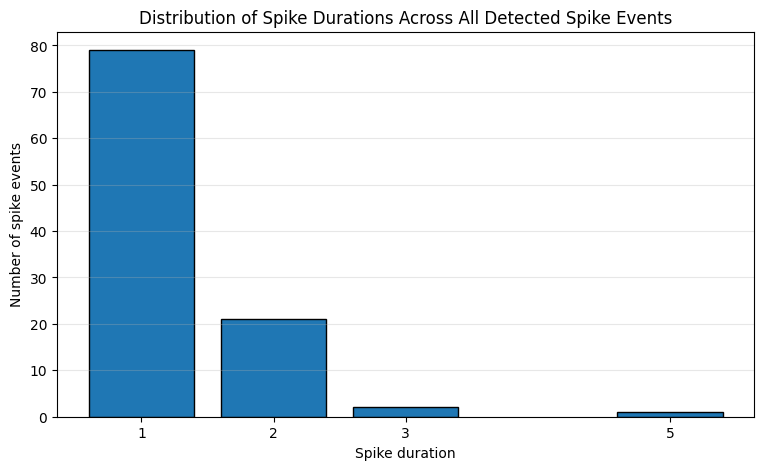

In [32]:
# --------------------------------------------------
#   Plot duration distribution
# --------------------------------------------------
duration_counts = (
    spike_events["duration_timesteps"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(9, 5))

plt.bar(
    duration_counts.index,
    duration_counts.values,
    edgecolor="black"
)

plt.title("Distribution of Spike Durations Across All Detected Spike Events")
plt.xlabel("Spike duration")
plt.ylabel("Number of spike events")
plt.xticks(duration_counts.index)
plt.grid(True, axis="y", alpha=0.3)

plt.show()

For every row in spike_candidates, we will ask:

1. Did this candidate last more than 1 timestep?
2. Which sensors are within 5 km of this sensor?
3. Did any of those neighbouring sensors also have a spike event at the same timestamp?
4. Did the neighbour spike have the same duration?
5. Based on that, should we label the spike as real or fake?


If target spike duration > 1
AND at least one neighbour within 5 km has a spike at the same timestamp
AND the neighbour has the same duration
THEN label = real

Otherwise, label = fake / isolated

In [33]:
# Make clean copies
spike_candidates = spike_candidates.copy()

spike_events_duration  = spike_events[[
    "sensor_id",
    "spike_event_id",
    "start_time",
    "end_time",
    "duration_timesteps",
    "max_pm2p5",
    "mean_pm2p5"
]].copy()

# Clean sensor IDs
spike_candidates["sensor_id"] = spike_candidates["sensor_id"].astype(str).str.strip().str.upper()
spike_events_duration["sensor_id"] = spike_events_duration["sensor_id"].astype(str).str.strip().str.upper()

# Make sure datetime columns are actually datetime
spike_candidates["timestamp"] = pd.to_datetime(spike_candidates["timestamp"])
spike_events_duration["start_time"] = pd.to_datetime(spike_events_duration["start_time"])
spike_events_duration["end_time"] = pd.to_datetime(spike_events_duration["end_time"])

# Create a unique ID for each spike candidate row
spike_candidates["_candidate_id"] = range(len(spike_candidates))

# Merge candidates with all possible events from the same sensor
candidate_event_matches = spike_candidates[[
    "_candidate_id",
    "sensor_id",
    "timestamp"
]].merge(
    spike_events_duration,
    on="sensor_id",
    how="left"
)

# Keep only the event where the candidate timestamp falls inside the event window
candidate_event_matches = candidate_event_matches[
    (candidate_event_matches["timestamp"] >= candidate_event_matches["start_time"]) &
    (candidate_event_matches["timestamp"] <= candidate_event_matches["end_time"])
].copy()

# In case there are duplicate matches, keep one event per candidate
candidate_event_matches = candidate_event_matches.drop_duplicates(
    subset=["_candidate_id"]
)

# Select the event-level features to attach back to spike_candidates
event_features = candidate_event_matches[[
    "_candidate_id",
    "spike_event_id",
    "start_time",
    "end_time",
    "duration_timesteps",
    "max_pm2p5",
    "mean_pm2p5"
]].rename(columns={
    "start_time": "event_start_time",
    "end_time": "event_end_time",
    "max_pm2p5": "event_max_pm2p5",
    "mean_pm2p5": "event_mean_pm2p5"
})

# Merge event duration/features back into spike_candidates
spike_candidates = spike_candidates.merge(
    event_features,
    on="_candidate_id",
    how="left"
)

# Remove helper column
spike_candidates = spike_candidates.drop(columns=["_candidate_id"])

spike_candidates.head()

,sensor_id,station,timestamp,pm2p5,rolling_mean,rolling_std,z_score,pm2p5_diff,spike_event_id,event_start_time,event_end_time,duration_timesteps,event_max_pm2p5,event_mean_pm2p5
0,004B122FD0F8,Midvaal Sicelo Library,2026-06-20 18:00:00,27.180000,10.075833,5.608677,3.049590,17.960000,1,2026-06-20 18:00:00,2026-06-20 18:00:00,1,27.180000,27.180000
1,351901936738230,Origin Centre (db),2026-06-17 17:00:00,67.187143,28.321011,9.670246,4.019146,31.138393,1,2026-06-17 17:00:00,2026-06-17 17:00:00,1,67.187143,67.187143
2,80F3DA50B704,Montgomery Park Node 1,2026-06-15 19:00:00,6.433333,2.109508,1.289612,3.352811,4.260606,1,2026-06-15 19:00:00,2026-06-15 19:00:00,1,6.433333,6.433333
3,80F3DA50B704,Montgomery Park Node 1,2026-06-21 16:00:00,1.008333,0.507260,0.165894,3.020443,0.283333,2,2026-06-21 16:00:00,2026-06-21 17:00:00,2,1.383333,1.195833
4,80F3DA50B704,Montgomery Park Node 1,2026-06-21 17:00:00,1.383333,0.547191,0.242760,3.444313,0.375000,2,2026-06-21 16:00:00,2026-06-21 17:00:00,2,1.383333,1.195833


In [34]:
neighbours = neighbours_within_5km[["sensor_id", "neighbour_sensor_id", "distance_km"]].copy()
spike_events_clean = spike_events.copy()
spike_candidates_clean = spike_candidates.copy()
# Clean sensor IDs
neighbours["sensor_id"] = neighbours["sensor_id"].astype(str).str.strip().str.upper()
neighbours["neighbour_sensor_id"] = neighbours["neighbour_sensor_id"].astype(str).str.strip().str.upper()
spike_candidates["sensor_id"] = spike_candidates["sensor_id"].astype(str).str.strip().str.upper()
spike_events_clean["sensor_id"] = spike_events_clean["sensor_id"].astype(str).str.strip().str.upper()

# Standardise timestamps
spike_candidates["timestamp"] = pd.to_datetime(spike_candidates["timestamp"])
spike_events_clean["start_time"] = pd.to_datetime(spike_events_clean["start_time"])
spike_events_clean["end_time"] = pd.to_datetime(spike_events_clean["end_time"])

Merging sensors with spike candidates with their neighbours

In [35]:
# spike candidates get unique ids because when merging with neighbours, we want to keep all rows even if they have the same sensor_id and timestamp
spike_candidates = spike_candidates.reset_index(drop=True)
spike_candidates["candidate_id"] = spike_candidates.index

# rename target duration column for clarity
spike_candidates = spike_candidates.rename(columns={
    "duration_timesteps": "target_duration_timesteps"
})

candidate_neighbour_pairs = spike_candidates.merge(
    neighbours,
    on="sensor_id",
    how="left"
)

candidate_neighbour_pairs.head(20)

,sensor_id,station,timestamp,pm2p5,rolling_mean,rolling_std,z_score,pm2p5_diff,spike_event_id,event_start_time,event_end_time,target_duration_timesteps,event_max_pm2p5,event_mean_pm2p5,candidate_id,neighbour_sensor_id,distance_km
0,004B122FD0F8,Midvaal Sicelo Library,2026-06-20 18:00:00,27.180000,10.075833,5.608677,3.049590,17.960000,1,2026-06-20 18:00:00,2026-06-20 18:00:00,1,27.180000,27.180000,0,NaN,NaN
1,351901936738230,Origin Centre (db),2026-06-17 17:00:00,67.187143,28.321011,9.670246,4.019146,31.138393,1,2026-06-17 17:00:00,2026-06-17 17:00:00,1,67.187143,67.187143,1,80F3DA50DE58,3.882644
2,351901936738230,Origin Centre (db),2026-06-17 17:00:00,67.187143,28.321011,9.670246,4.019146,31.138393,1,2026-06-17 17:00:00,2026-06-17 17:00:00,1,67.187143,67.187143,1,80F3DA5493DC,1.765730
3,351901936738230,Origin Centre (db),2026-06-17 17:00:00,67.187143,28.321011,9.670246,4.019146,31.138393,1,2026-06-17 17:00:00,2026-06-17 17:00:00,1,67.187143,67.187143,1,80F3DA557E14,4.415646
4,351901936738230,Origin Centre (db),2026-06-17 17:00:00,67.187143,28.321011,9.670246,4.019146,31.138393,1,2026-06-17 17:00:00,2026-06-17 17:00:00,1,67.187143,67.187143,1,80F3DA558251,1.867351
5,80F3DA50B704,Montgomery Park Node 1,2026-06-15 19:00:00,6.433333,2.109508,1.289612,3.352811,4.260606,1,2026-06-15 19:00:00,2026-06-15 19:00:00,1,6.433333,6.433333,2,80F3DA50DE58,4.383942
6,80F3DA50B704,Montgomery Park Node 1,2026-06-15 19:00:00,6.433333,2.109508,1.289612,3.352811,4.260606,1,2026-06-15 19:00:00,2026-06-15 19:00:00,1,6.433333,6.433333,2,80F3DA53D73C,3.495640
7,80F3DA50B704,Montgomery Park Node 1,2026-06-15 19:00:00,6.433333,2.109508,1.289612,3.352811,4.260606,1,2026-06-15 19:00:00,2026-06-15 19:00:00,1,6.433333,6.433333,2,80F3DA53FFDC,3.950889
8,80F3DA50B704,Montgomery Park Node 1,2026-06-15 19:00:00,6.433333,2.109508,1.289612,3.352811,4.260606,1,2026-06-15 19:00:00,2026-06-15 19:00:00,1,6.433333,6.433333,2,80F3DA540038,3.927428
9,80F3DA50B704,Montgomery Park Node 1,2026-06-15 19:00:00,6.433333,2.109508,1.289612,3.352811,4.260606,1,2026-06-15 19:00:00,2026-06-15 19:00:00,1,6.433333,6.433333,2,80F3DA547384,4.580760


In [36]:
# if a sensor has no neighbours within 5 km, you should not confidently call it fake. You simply do not have enough spatial evidence.
neighbour_counts = (
    candidate_neighbour_pairs
    .groupby("candidate_id")
    .agg(
        n_neighbours_checked=("neighbour_sensor_id", "nunique")
    )
    .reset_index()
)

neighbour_counts.head(5)

,candidate_id,n_neighbours_checked
0,0,0
1,1,4
2,2,6
3,3,6
4,4,6


In [37]:
neighbour_events = spike_events_clean[[
    "sensor_id",
    "spike_event_id",
    "start_time",
    "end_time",
    "duration_timesteps"
]].copy()

neighbour_events = neighbour_events.rename(columns={
    "sensor_id": "neighbour_sensor_id",
    "spike_event_id": "neighbour_spike_event_id",
    "start_time": "neighbour_start_time",
    "end_time": "neighbour_end_time",
    "duration_timesteps": "neighbour_duration_timesteps"
})

neighbour_events.head(20)

,neighbour_sensor_id,neighbour_spike_event_id,neighbour_start_time,neighbour_end_time,neighbour_duration_timesteps
0,004B122FD0F8,1,2026-06-20 18:00:00,2026-06-20 18:00:00,1
1,351901936738230,1,2026-06-17 17:00:00,2026-06-17 17:00:00,1
2,80F3DA50B704,1,2026-06-15 19:00:00,2026-06-15 19:00:00,1
3,80F3DA50B704,2,2026-06-21 16:00:00,2026-06-21 17:00:00,2
4,80F3DA50BD74,1,2026-06-17 12:00:00,2026-06-17 12:00:00,1
5,80F3DA50BD74,2,2026-06-18 06:00:00,2026-06-18 06:00:00,1
6,80F3DA50BD74,3,2026-06-19 08:00:00,2026-06-19 08:00:00,1
7,80F3DA50DE3C,1,2026-06-15 21:00:00,2026-06-15 21:00:00,1
8,80F3DA50DE3C,2,2026-06-18 19:00:00,2026-06-18 19:00:00,1
9,80F3DA50DE3C,3,2026-06-19 18:00:00,2026-06-19 18:00:00,1


In [38]:
# merge candidate_neighbour_pairs with neighbour_events to get the duration of the neighbour events
candidate_neighbour_events = candidate_neighbour_pairs.merge(
    neighbour_events,
    on="neighbour_sensor_id",
    how="left"
)

candidate_neighbour_events.head(5)

,sensor_id,station,timestamp,pm2p5,rolling_mean,rolling_std,z_score,pm2p5_diff,spike_event_id,event_start_time,...,target_duration_timesteps,event_max_pm2p5,event_mean_pm2p5,candidate_id,neighbour_sensor_id,distance_km,neighbour_spike_event_id,neighbour_start_time,neighbour_end_time,neighbour_duration_timesteps
0,004B122FD0F8,Midvaal Sicelo Library,2026-06-20 18:00:00,27.180000,10.075833,5.608677,3.049590,17.960000,1,2026-06-20 18:00:00,...,1,27.180000,27.180000,0,NaN,NaN,NaN,NaT,NaT,NaN
1,351901936738230,Origin Centre (db),2026-06-17 17:00:00,67.187143,28.321011,9.670246,4.019146,31.138393,1,2026-06-17 17:00:00,...,1,67.187143,67.187143,1,80F3DA50DE58,3.882644,1.0,2026-06-15 18:00:00,2026-06-15 19:00:00,2.0
2,351901936738230,Origin Centre (db),2026-06-17 17:00:00,67.187143,28.321011,9.670246,4.019146,31.138393,1,2026-06-17 17:00:00,...,1,67.187143,67.187143,1,80F3DA5493DC,1.765730,1.0,2026-06-16 22:00:00,2026-06-16 22:00:00,1.0
3,351901936738230,Origin Centre (db),2026-06-17 17:00:00,67.187143,28.321011,9.670246,4.019146,31.138393,1,2026-06-17 17:00:00,...,1,67.187143,67.187143,1,80F3DA5493DC,1.765730,2.0,2026-06-17 18:00:00,2026-06-17 18:00:00,1.0
4,351901936738230,Origin Centre (db),2026-06-17 17:00:00,67.187143,28.321011,9.670246,4.019146,31.138393,1,2026-06-17 17:00:00,...,1,67.187143,67.187143,1,80F3DA557E14,4.415646,1.0,2026-06-21 17:00:00,2026-06-21 17:00:00,1.0


The target sensor spiked at this timestamp.
Was the neighbour also inside a spike event at that same timestamp?

In [39]:
# Keep only the rows where the candidate timestamp falls within the neighbour event window
active_neighbour_events = candidate_neighbour_events[
    (candidate_neighbour_events["timestamp"] >= candidate_neighbour_events["neighbour_start_time"]) &
    (candidate_neighbour_events["timestamp"] <= candidate_neighbour_events["neighbour_end_time"])
].copy()

### MAIN CONDITION: Target spike lasted more than 1 timestep AND neighbour spike duration equals target spike duration

In [40]:
active_neighbour_events["same_duration_match"] = (
    (active_neighbour_events["target_duration_timesteps"] > 1) &
    (active_neighbour_events["neighbour_duration_timesteps"] == active_neighbour_events["target_duration_timesteps"])
)

active_neighbour_events[
    [
        "candidate_id",
        "sensor_id",
        "timestamp",
        "target_duration_timesteps",
        "neighbour_sensor_id",
        "distance_km",
        "neighbour_start_time",
        "neighbour_end_time",
        "neighbour_duration_timesteps",
        "same_duration_match"
    ]
].head(5)

,candidate_id,sensor_id,timestamp,target_duration_timesteps,neighbour_sensor_id,distance_km,neighbour_start_time,neighbour_end_time,neighbour_duration_timesteps,same_duration_match
6,2,80F3DA50B704,2026-06-15 19:00:00,1,80F3DA50DE58,4.383942,2026-06-15 18:00:00,2026-06-15 19:00:00,2.0,False
23,4,80F3DA50B704,2026-06-21 17:00:00,2,80F3DA557E14,2.622553,2026-06-21 17:00:00,2026-06-21 17:00:00,1.0,False
24,5,80F3DA50BD74,2026-06-17 12:00:00,1,80F3DA53A570,4.091257,2026-06-17 12:00:00,2026-06-17 12:00:00,1.0,False
27,5,80F3DA50BD74,2026-06-17 12:00:00,1,80F3DA546CB8,0.983162,2026-06-17 12:00:00,2026-06-17 12:00:00,1.0,False
59,12,80F3DA50DE58,2026-06-15 19:00:00,2,80F3DA50B704,4.383942,2026-06-15 19:00:00,2026-06-15 19:00:00,1.0,False


### General Evidence
*n_neighbours_checked*:
How many nearby sensors were available?

*n_active_neighbour_spikes*:
How many nearby sensors were also spiking at that timestamp?

*n_same_duration_neighbours*:
How many nearby sensors had the same spike duration?

In [41]:
neighbour_counts = (
    candidate_neighbour_pairs
    .groupby("candidate_id")
    .agg(
        n_neighbours_checked=("neighbour_sensor_id", "nunique")
    )
    .reset_index()
)

active_neighbour_summary = (
    active_neighbour_events
    .groupby("candidate_id")
    .agg(
        n_active_neighbour_spikes=("neighbour_sensor_id", "nunique"),
        max_neighbour_duration=("neighbour_duration_timesteps", "max"),
        mean_neighbour_duration=("neighbour_duration_timesteps", "mean")
    )
    .reset_index()
)

same_duration_summary = (
    active_neighbour_events[active_neighbour_events["same_duration_match"]]
    .groupby("candidate_id")
    .agg(
        n_same_duration_neighbours=("neighbour_sensor_id", "nunique"),
        matching_neighbour_ids=("neighbour_sensor_id", lambda x: ", ".join(sorted(x.unique())))
    )
    .reset_index()
)

In [43]:
labelled_spike_candidates = spike_candidates.merge(
    neighbour_counts,
    on="candidate_id",
    how="left"
)

labelled_spike_candidates = labelled_spike_candidates.merge(
    active_neighbour_summary,
    on="candidate_id",
    how="left"
)

labelled_spike_candidates = labelled_spike_candidates.merge(
    same_duration_summary,
    on="candidate_id",
    how="left"
)

# Fill missing evidence with 0
fill_cols = [
    "n_neighbours_checked",
    "n_active_neighbour_spikes",
    "n_same_duration_neighbours",
    "max_neighbour_duration",
    "mean_neighbour_duration"
]

for col in fill_cols:
    labelled_spike_candidates[col] = labelled_spike_candidates[col].fillna(0)

labelled_spike_candidates["matching_neighbour_ids"] = (
    labelled_spike_candidates["matching_neighbour_ids"].fillna("")
)

In [44]:
conditions = [
    labelled_spike_candidates["target_duration_timesteps"] <= 1,

    labelled_spike_candidates["n_neighbours_checked"] == 0,

    (
        (labelled_spike_candidates["target_duration_timesteps"] > 1) &
        (labelled_spike_candidates["n_same_duration_neighbours"] >= 1)
    ),

    (
        (labelled_spike_candidates["target_duration_timesteps"] > 1) &
        (labelled_spike_candidates["n_neighbours_checked"] > 0) &
        (labelled_spike_candidates["n_active_neighbour_spikes"] == 0)
    ),

    (
        (labelled_spike_candidates["target_duration_timesteps"] > 1) &
        (labelled_spike_candidates["n_active_neighbour_spikes"] > 0) &
        (labelled_spike_candidates["n_same_duration_neighbours"] == 0)
    )
]

choices = [
    "fake_short_duration",
    "uncertain_no_neighbours",
    "real_same_duration_neighbour",
    "fake_isolated_no_neighbour_spike",
    "uncertain_neighbour_spike_different_duration"
]

labelled_spike_candidates["rule_label"] = np.select(
    conditions,
    choices,
    default="uncertain"
)

labelled_spike_candidates["binary_label"] = np.where(
    labelled_spike_candidates["rule_label"] == "real_same_duration_neighbour",
    "real",
    "fake"
)

In [49]:
labelled_spike_candidates["rule_label"].value_counts()

rule_label
fake_short_duration                             79
uncertain_no_neighbours                         28
fake_isolated_no_neighbour_spike                17
uncertain_neighbour_spike_different_duration     4
real_same_duration_neighbour                     4
Name: count, dtype: int64

In [48]:
labelled_spike_candidates["binary_label"].value_counts()

binary_label
fake    128
real      4
Name: count, dtype: int64

In [50]:
# Real spike candidates with at least one neighbour spike of the same duration
labelled_spike_candidates[
    labelled_spike_candidates["binary_label"] == "real"
].sort_values("z_score", ascending=False).head(20)

,sensor_id,station,timestamp,pm2p5,rolling_mean,rolling_std,z_score,pm2p5_diff,spike_event_id,event_start_time,...,event_mean_pm2p5,candidate_id,n_neighbours_checked,n_active_neighbour_spikes,max_neighbour_duration,mean_neighbour_duration,n_same_duration_neighbours,matching_neighbour_ids,rule_label,binary_label
117,80F3DA558250,Braamfischer,2026-06-17 19:00:00,64.409091,16.017393,14.171042,3.414830,22.909091,2,2026-06-17 19:00:00,...,70.362879,117,2,1.0,2.0,2.0,1.0,80F3DA550F78,real_same_duration_neighbour,real
91,80F3DA550F78,J.B Marks Secondary,2026-06-17 19:00:00,69.316667,19.730366,15.526857,3.193583,32.966667,1,2026-06-17 19:00:00,...,76.241667,91,2,1.0,2.0,2.0,1.0,80F3DA558250,real_same_duration_neighbour,real
118,80F3DA558250,Braamfischer,2026-06-17 20:00:00,76.316667,17.885133,18.570282,3.146508,11.907576,2,2026-06-17 19:00:00,...,70.362879,118,2,1.0,2.0,2.0,1.0,80F3DA550F78,real_same_duration_neighbour,real
92,80F3DA550F78,J.B Marks Secondary,2026-06-17 20:00:00,83.166667,22.307386,20.223936,3.009270,13.850000,1,2026-06-17 19:00:00,...,76.241667,92,2,1.0,2.0,2.0,1.0,80F3DA558250,real_same_duration_neighbour,real


In [51]:
# Fake spike candidates with no neighbour spikes of the same duration
labelled_spike_candidates[
    labelled_spike_candidates["binary_label"] == "fake"
].sort_values("z_score", ascending=False).head(20)

,sensor_id,station,timestamp,pm2p5,rolling_mean,rolling_std,z_score,pm2p5_diff,spike_event_id,event_start_time,...,event_mean_pm2p5,candidate_id,n_neighbours_checked,n_active_neighbour_spikes,max_neighbour_duration,mean_neighbour_duration,n_same_duration_neighbours,matching_neighbour_ids,rule_label,binary_label
64,80F3DA546CB8,Gstad West,2026-06-17 22:00:00,492.041667,30.743971,98.584335,4.679219,481.925000,2,2026-06-17 22:00:00,...,492.041667,64,1,0.0,0.0,0.0,0.0,,fake_short_duration,fake
28,80F3DA53CDFC,Wrdm Hectorton,2026-06-17 17:00:00,163.083333,15.512144,31.561774,4.675630,152.283333,1,2026-06-17 17:00:00,...,194.650000,28,1,0.0,0.0,0.0,0.0,,fake_isolated_no_neighbour_spike,fake
72,80F3DA549348,Lavin,2026-06-17 14:00:00,34.590000,4.770086,6.390412,4.666352,30.462727,1,2026-06-17 14:00:00,...,34.590000,72,1,0.0,0.0,0.0,0.0,,fake_short_duration,fake
80,80F3DA54B464,Boksburg 1,2026-06-16 17:00:00,234.508333,18.713138,46.431426,4.647611,197.644697,1,2026-06-16 16:00:00,...,135.685985,80,0,0.0,0.0,0.0,0.0,,uncertain_no_neighbours,fake
122,80F3DA558BC0,Kyalami 1,2026-06-21 12:00:00,30.350000,3.734943,5.729063,4.645622,27.395455,2,2026-06-21 12:00:00,...,30.350000,122,2,0.0,0.0,0.0,0.0,,fake_short_duration,fake
96,80F3DA551440,SYNERGIA Leeds 4,2026-06-16 20:00:00,208.141667,12.188937,42.220208,4.641207,206.641667,3,2026-06-16 20:00:00,...,208.141667,96,1,0.0,0.0,0.0,0.0,,fake_short_duration,fake
31,80F3DA53CDFC,Wrdm Hectorton,2026-06-21 06:00:00,108.733333,10.962879,21.119818,4.629323,106.216667,3,2026-06-21 06:00:00,...,108.733333,31,1,0.0,0.0,0.0,0.0,,fake_short_duration,fake
24,80F3DA53A570,Vlakfontein 599,2026-06-17 12:00:00,56.041667,8.031313,10.557798,4.547383,46.205303,1,2026-06-17 12:00:00,...,56.041667,24,3,2.0,1.0,1.0,0.0,,fake_short_duration,fake
41,80F3DA542CDC,Rusfontein 1,2026-06-17 12:00:00,55.890000,5.862001,11.045663,4.529198,39.390000,2,2026-06-17 11:00:00,...,46.616111,41,0,0.0,0.0,0.0,0.0,,uncertain_no_neighbours,fake
98,80F3DA551440,SYNERGIA Leeds 4,2026-06-20 17:00:00,8.200000,0.886490,1.644500,4.447254,7.766667,5,2026-06-20 17:00:00,...,8.200000,98,1,0.0,0.0,0.0,0.0,,fake_short_duration,fake
